# Supplemental Personality Datasets: EDA and Story Ideas

This notebook examines the three new datasets alongside the original behavior survey, with a specific goal: find what each source can add to a scrollytelling story, and determine whether any records can legitimately be combined.

## Important distinction

The datasets do **not** contain shared respondent IDs. They are separate surveys with different instruments and collection periods. Their records must not be concatenated as if they were one sample. The 50-item BIG5 and IPIP questionnaires share the same item wording, and MIES shares eight extraversion items with them; these enable carefully labeled comparisons, not respondent-level joins.

IPIP is large (over 400 MB), so it is read in chunks and only the needed columns are loaded.


In [1]:
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_context("notebook")

DATA = Path("data")
behavior = pd.read_csv(DATA / "personality_dataset.csv")
big5 = pd.read_csv(DATA / "BIG5" / "data.csv", sep="\t")
mies = pd.read_csv(DATA / "MIES_Dev_Data" / "data.csv", sep="\t")

print(f"Behavior survey: {len(behavior):,} rows, {behavior.shape[1]} columns")
print(f"BIG5: {len(big5):,} rows, {big5.shape[1]} columns")
print(f"MIES: {len(mies):,} rows, {mies.shape[1]} columns")


Behavior survey: 2,900 rows, 8 columns
BIG5: 19,719 rows, 57 columns
MIES: 7,188 rows, 282 columns


## 1. What each dataset measures

| Dataset | Measurement | Extra context | Main use in this project |
|---|---|---|---|
| Original behavior survey | Seven reported behaviors plus Introvert/Extrovert label | No demographic fields | Concrete behavior stories |
| BIG5 | 50 IPIP Big-Five items | Age, gender, country, race, source | Five-trait profile and sample context |
| IPIP-FFM | Same 50 Big-Five items; item order/timing metadata | Country and repeat-IP indicator (`IPC`) | Large-scale replication of trait patterns |
| MIES | 91 items, including eight that match Big-Five extraversion items | Age, gender, country, and self-identification (`IE`) | Compare self-label with a continuous extraversion score |

Dates in the codebooks differ: BIG5 is described as collected circa 2012, IPIP as 2016–2018, and the MIES file contains 2019 records. Differences between samples are not automatically changes over time.


,rows,columns,exact_duplicate_rows
dataset,,,
Behavior survey,2900,8,388
BIG5,19719,57,0
MIES,7188,282,0


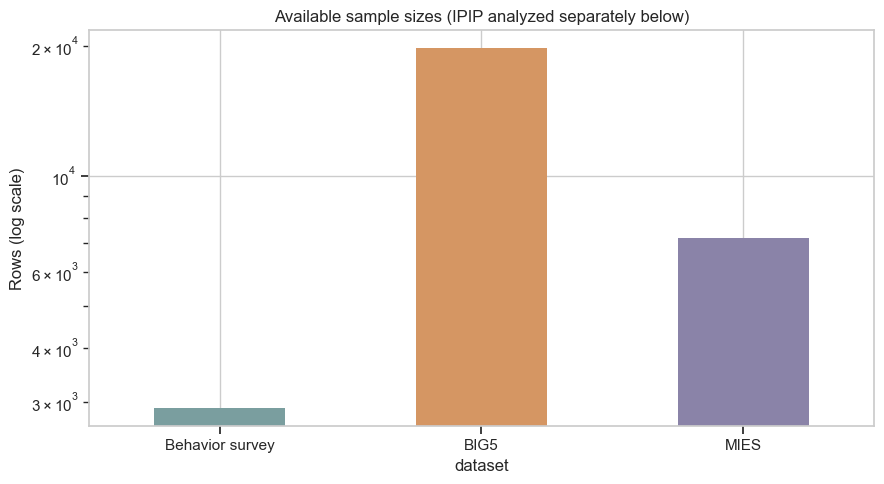

In [2]:
dataset_summary = pd.DataFrame([
    {"dataset": "Behavior survey", "rows": len(behavior), "columns": behavior.shape[1],
     "exact_duplicate_rows": int(behavior.duplicated().sum())},
    {"dataset": "BIG5", "rows": len(big5), "columns": big5.shape[1],
     "exact_duplicate_rows": int(big5.duplicated().sum())},
    {"dataset": "MIES", "rows": len(mies), "columns": mies.shape[1],
     "exact_duplicate_rows": int(mies.duplicated().sum())},
]).set_index("dataset")
display(dataset_summary)

fig, ax = plt.subplots(figsize=(9, 5))
dataset_summary["rows"].plot.bar(ax=ax, color=["#7A9E9F", "#D59663", "#8A83A8"])
ax.set_yscale("log")
ax.set_ylabel("Rows (log scale)")
ax.set_title("Available sample sizes (IPIP analyzed separately below)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()


The behavior survey has a substantial exact-duplicate rate from the earlier EDA. Identical records may be duplicate submissions or coincidentally identical responses; without respondent IDs, do not silently delete them. Report the duplicate sensitivity or treat the original label dataset cautiously.


## 2. Scoring the shared Big-Five questionnaire

Both BIG5 and IPIP contain the same 50 item wordings and use 1–5 responses. The code below computes each trait as a respondent's mean across its ten items after reversing negatively keyed items (`6 - response`). Zeros are treated as unanswered values. This makes trait scores interpretable on the original 1–5 scale; it is not a clinical or diagnostic measure.


In [3]:
TRAITS = {
    "Extraversion": ("E", [2, 4, 6, 8, 10]),
    "Neuroticism": ("N", [2, 4]),
    "Agreeableness": ("A", [1, 3, 5, 7]),
    "Conscientiousness": ("C", [2, 4, 6, 8]),
    "Openness": ("O", [2, 4, 6]),
}
BIG5_PREFIXES = {"E": "E", "N": "N", "A": "A", "C": "C", "O": "O"}
IPIP_PREFIXES = {"E": "EXT", "N": "EST", "A": "AGR", "C": "CSN", "O": "OPN"}

def score_traits(frame, prefix_map):
    scores = {}
    for trait, (short_name, reverse_items) in TRAITS.items():
        prefix = prefix_map[short_name]
        columns = [f"{prefix}{item}" for item in range(1, 11)]
        values = frame[columns].replace(0, np.nan).astype(float).copy()
        for item in reverse_items:
            values[f"{prefix}{item}"] = 6 - values[f"{prefix}{item}"]
        scores[trait] = values.mean(axis=1)
    return pd.DataFrame(scores, index=frame.index)

big5_scores = score_traits(big5, BIG5_PREFIXES)
big5_score_summary = big5_scores.describe().T
display(big5_score_summary)
print("BIG5 rows with at least one unanswered Big-Five item:",
      int(big5_scores.isna().any(axis=1).sum()))


,count,mean,std,min,25%,50%,75%,max
Extraversion,"19,718.000",3.011,0.922,1.000,2.300,3.000,3.700,5.000
Neuroticism,"19,718.000",3.097,0.862,1.000,2.500,3.100,3.700,5.000
Agreeableness,"19,718.000",3.845,0.715,1.000,3.400,3.900,4.400,5.000
Conscientiousness,"19,718.000",3.347,0.731,1.000,2.800,3.400,3.900,5.000
Openness,"19,718.000",3.909,0.626,1.000,3.500,4.000,4.400,5.000


BIG5 rows with at least one unanswered Big-Five item: 1


,valid_age_13_to_100,invalid_or_missing_age,valid_age_percent
BIG5,"19,636.000",83.000,99.580
MIES,"7,178.000",10.000,99.860


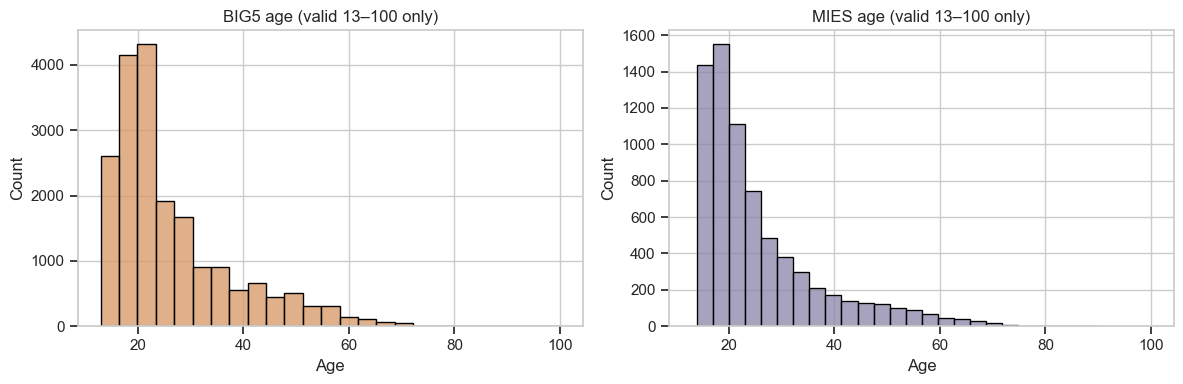

In [4]:
# Ages above 100 are treated as implausible entries for descriptive summaries.
def clean_age(series):
    age = pd.to_numeric(series, errors="coerce")
    return age.where(age.between(13, 100))

big5_age = clean_age(big5["age"])
mies_age = clean_age(mies["age"])

demographic_quality = pd.DataFrame({
    "BIG5": {
        "valid_age_13_to_100": int(big5_age.notna().sum()),
        "invalid_or_missing_age": int(big5_age.isna().sum()),
        "valid_age_percent": 100 * big5_age.notna().mean(),
    },
    "MIES": {
        "valid_age_13_to_100": int(mies_age.notna().sum()),
        "invalid_or_missing_age": int(mies_age.isna().sum()),
        "valid_age_percent": 100 * mies_age.notna().mean(),
    },
}).T
display(demographic_quality.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
sns.histplot(big5_age.dropna(), bins=25, color="#D59663", ax=axes[0])
axes[0].set_title("BIG5 age (valid 13–100 only)")
axes[0].set_xlabel("Age")
sns.histplot(mies_age.dropna(), bins=25, color="#8A83A8", ax=axes[1])
axes[1].set_title("MIES age (valid 13–100 only)")
axes[1].set_xlabel("Age")
plt.tight_layout()


The BIG5 and MIES codebooks say ages were entered by respondents. The raw files include implausible values, so the charts use an explicit 13–100 range rather than the raw mean. This range is a descriptive cleaning rule, not evidence that every excluded response is fraudulent.


## 3. Large-scale IPIP data (chunked)

The IPIP file contains answer items, question timing, survey metadata, and repeat-IP counts. To avoid loading the full 416 MB file into memory, this cell reads just the 50 answers, country, and `IPC` field in chunks. The codebook recommends `IPC == 1` for the cleanest one-record-per-IP subset; shared networks can make this filter imperfect, so retain that caveat.


In [5]:
IPIP_PREFIXES = {"E": "EXT", "N": "EST", "A": "AGR", "C": "CSN", "O": "OPN"}
ipip_item_columns = [
    f"{prefix}{item}"
    for prefix in IPIP_PREFIXES.values()
    for item in range(1, 11)
]
ipip_usecols = ipip_item_columns + ["IPC", "country"]

ipip_rows = 0
ipip_ipc1_rows = 0
ipip_zero_cells = 0
ipip_country_counts = Counter()
ipip_ipc_counts = Counter()
ipip_score_sums = pd.Series(0.0, index=TRAITS)
ipip_score_counts = pd.Series(0, index=TRAITS, dtype="int64")
ipip_score_samples = []
sampled_rows = 0

for chunk in pd.read_csv(
    DATA / "IPIP-FFM-data-8Nov2018" / "data-final.csv",
    sep="\t",
    usecols=ipip_usecols,
    chunksize=50000,
):
    ipip_rows += len(chunk)
    ipip_ipc_counts.update(chunk["IPC"].value_counts(dropna=False).to_dict())
    once = chunk.loc[chunk["IPC"].eq(1)]
    ipip_ipc1_rows += len(once)
    ipip_zero_cells += int((once[ipip_item_columns] == 0).sum().sum())
    ipip_country_counts.update(once["country"].fillna("(missing)").value_counts().to_dict())

    scores = score_traits(once, IPIP_PREFIXES)
    ipip_score_sums += scores.sum()
    ipip_score_counts += scores.count()

    if sampled_rows < 40000:
        part = scores.sample(
            n=min(2000, 40000 - sampled_rows, len(scores)),
            random_state=42,
        )
        ipip_score_samples.append(part)
        sampled_rows += len(part)

ipip_score_sample = pd.concat(ipip_score_samples, ignore_index=True)
ipip_score_means = ipip_score_sums / ipip_score_counts

print(f"IPIP total rows: {ipip_rows:,}")
print(f"IPIP IPC=1 rows: {ipip_ipc1_rows:,} ({100 * ipip_ipc1_rows / ipip_rows:.1f}%)")
print(f"IPIP zero response cells among IPC=1 rows: {ipip_zero_cells:,}")
print(f"Rows in the IPIP plot sample: {len(ipip_score_sample):,}")
print("Most common countries in IPC=1 records:")
display(pd.Series(ipip_country_counts).sort_values(ascending=False).head(10).rename("rows").to_frame())
display(ipip_score_sample.describe().T)


IPIP total rows: 1,015,341
IPIP IPC=1 rows: 696,845 (68.6%)
IPIP zero response cells among IPC=1 rows: 234,989
Rows in the IPIP plot sample: 40,000
Most common countries in IPC=1 records:


,rows
US,345443
GB,49803
CA,43843
AU,34886
DE,12327
IN,12218
PH,11136
MX,9874
NONE,9614
NO,8941


,count,mean,std,min,25%,50%,75%,max
Extraversion,"39,867.000",2.915,0.910,1.000,2.200,2.900,3.600,5.000
Neuroticism,"39,858.000",3.080,0.860,1.000,2.500,3.100,3.700,5.000
Agreeableness,"39,861.000",3.764,0.736,1.000,3.300,3.889,4.300,5.000
Conscientiousness,"39,860.000",3.340,0.738,1.000,2.800,3.300,3.900,5.000
Openness,"39,855.000",3.930,0.619,1.000,3.500,4.000,4.400,5.000


## 4. BIG5 vs. IPIP: converging trait profiles

These are separate, self-selected online samples, not a time series or one combined cohort. Since the 50 items are shared, compare scored distributions as a cross-source consistency check. The IPIP plot uses a deterministic sample of up to 40,000 respondents; its means below use all `IPC == 1` records.


,BIG5 (all records),"IPIP (IPC=1, all records)",IPIP minus BIG5
Extraversion,3.011,2.921,-0.091
Neuroticism,3.097,3.084,-0.013
Agreeableness,3.845,3.759,-0.085
Conscientiousness,3.347,3.341,-0.007
Openness,3.909,3.929,0.020


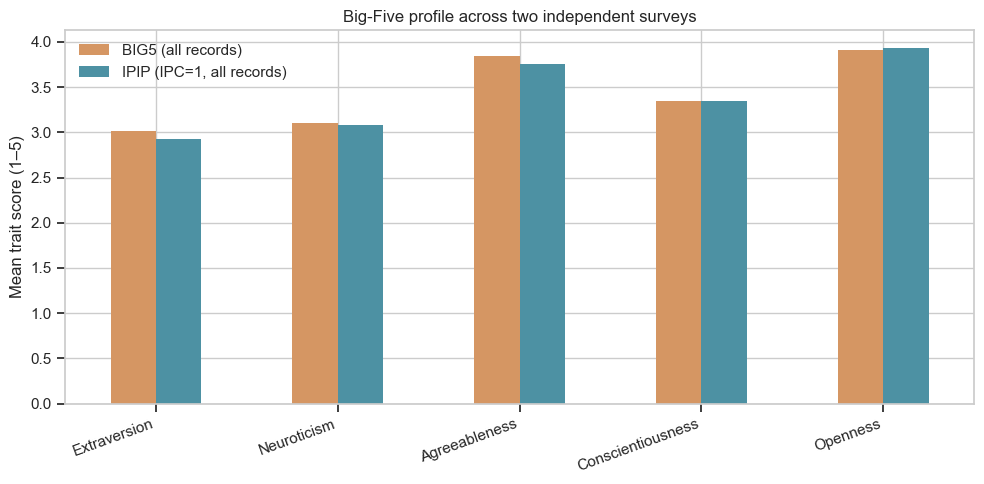

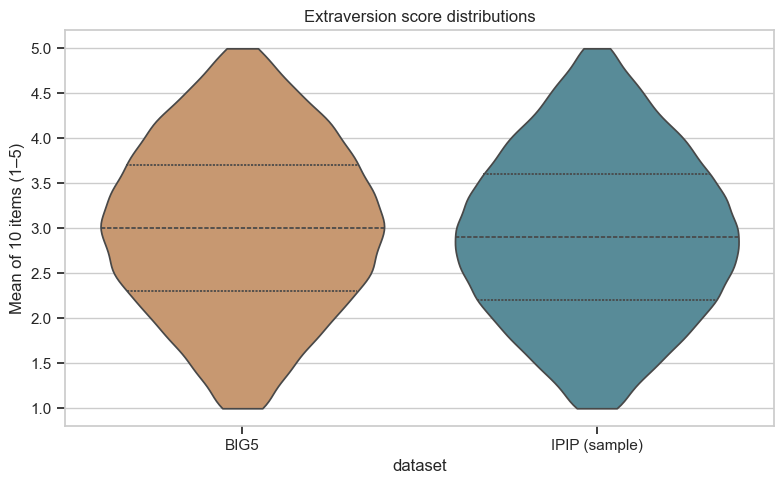

In [6]:
profile_means = pd.DataFrame({
    "BIG5 (all records)": big5_scores.mean(),
    "IPIP (IPC=1, all records)": ipip_score_means,
})
profile_means["IPIP minus BIG5"] = (
    profile_means["IPIP (IPC=1, all records)"] - profile_means["BIG5 (all records)"]
)
display(profile_means.round(3))

profile_means[["BIG5 (all records)", "IPIP (IPC=1, all records)"]].plot(
    kind="bar", figsize=(10, 5), color=["#D59663", "#4D91A3"]
)
plt.ylabel("Mean trait score (1–5)")
plt.title("Big-Five profile across two independent surveys")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plot_traits = pd.concat([
    big5_scores[["Extraversion"]].assign(dataset="BIG5"),
    ipip_score_sample[["Extraversion"]].assign(dataset="IPIP (sample)"),
], ignore_index=True)
fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=plot_traits, x="dataset", y="Extraversion",
               hue="dataset", palette={"BIG5": "#D59663", "IPIP (sample)": "#4D91A3"},
               legend=False, inner="quart", cut=0, ax=ax)
ax.set_title("Extraversion score distributions")
ax.set_ylabel("Mean of 10 items (1–5)")
plt.tight_layout()


The two mean profiles are close overall (largest absolute difference is about 0.09 points on the 1–5 scale in these data). That supports using the shared instrument for a cautious side-by-side comparison. It does **not** prove population representativeness or a historical trend: sampling, site traffic, language, and collection procedures may differ.


## 5. MIES: self-identification vs. shared extraversion items

MIES asks whether respondents identify as introverts, extroverts, or neither (`IE`: 1, 2, 3). Its Q81–Q85 and Q89–Q91 items match eight of the Big-Five extraversion questions. Reverse the five low-extraversion statements, then average the eight responses. Exclude `IE == 0` from labeled comparisons; do not treat "neither" as missing.


,responses
IE,
1,4404
3,1769
2,990
0,25


,count,mean,median,std
identity,,,,
Neither,1769,3.134,3.125,0.843
Self-identifies extrovert,990,4.078,4.250,0.700
Self-identifies introvert,4404,2.175,2.125,0.772


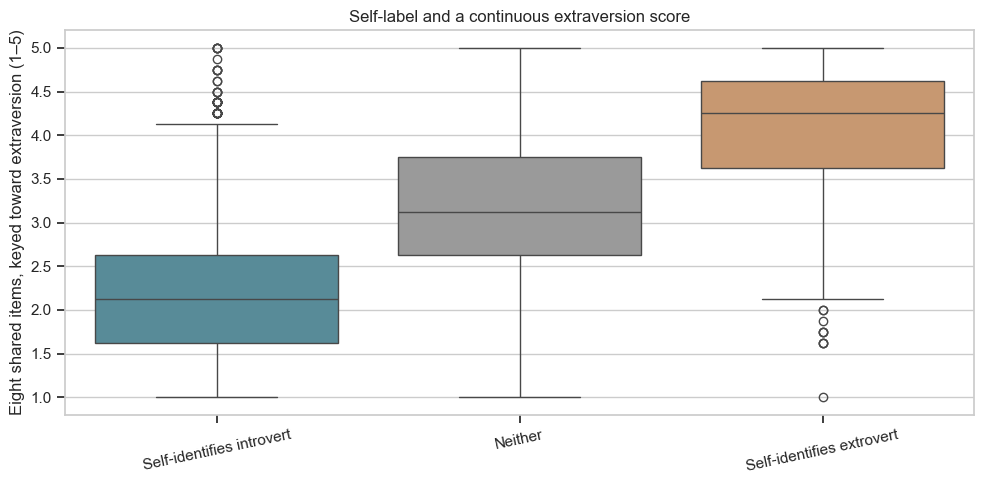

In [7]:
mies_item_key = {
    81: False,  # quiet around strangers
    82: False,  # don't talk a lot
    83: False,  # keep in the background
    84: False,  # don't like to draw attention
    85: False,  # have little to say
    89: True,   # don't mind being center of attention
    90: True,   # start conversations
    91: True,   # talk to many people at parties
}
mies_shared_items = {}
for question, positive in mies_item_key.items():
    response = mies[f"Q{question}A"].replace(0, np.nan).astype(float)
    mies_shared_items[f"Q{question}"] = response if positive else 6 - response
mies_extraversion = pd.DataFrame(mies_shared_items).mean(axis=1)
mies_identity = mies["IE"].map({
    1: "Self-identifies introvert",
    2: "Self-identifies extrovert",
    3: "Neither",
})
mies_identity_summary = (
    pd.DataFrame({"identity": mies_identity, "shared_item_extraversion": mies_extraversion})
      .dropna(subset=["identity"])
      .groupby("identity")["shared_item_extraversion"]
      .agg(["count", "mean", "median", "std"])
)
display(mies["IE"].value_counts(dropna=False).rename("responses").to_frame())
display(mies_identity_summary.round(3))

fig, ax = plt.subplots(figsize=(10, 5))
plot_mies = pd.DataFrame({
    "identity": mies_identity,
    "shared_item_extraversion": mies_extraversion,
}).dropna(subset=["identity"])
order = ["Self-identifies introvert", "Neither", "Self-identifies extrovert"]
sns.boxplot(data=plot_mies, x="identity", y="shared_item_extraversion",
            order=order, hue="identity",
            palette={"Self-identifies introvert": "#4D91A3",
                     "Neither": "#9A9A9A",
                     "Self-identifies extrovert": "#D59663"},
            legend=False, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Eight shared items, keyed toward extraversion (1–5)")
ax.set_title("Self-label and a continuous extraversion score")
ax.tick_params(axis="x", rotation=12)
plt.tight_layout()


In this sample, the eight-item average separates the self-identified introvert and extrovert groups, while "neither" falls between them. The overlap in the boxplots is a useful story point: a personality label is not a perfect measurement boundary. MIES respondents were asked to identify themselves; this comparison is association, not validation of a diagnosis.


## 6. Demographic scope and limits

BIG5 and MIES have age, gender, and country fields; IPIP only has country among these contextual fields. The following summaries make the coverage visible, but country reflects technical/network location and is not a verified residence. Demographic data are self-reported or incomplete, and the online samples are convenience samples.


In [8]:
gender_labels = {0: "Missing/other code", 1: "Male", 2: "Female", 3: "Other"}
big5_gender = big5["gender"].map(gender_labels).fillna("Unmapped")
mies_gender = mies["gender"].map(gender_labels).fillna("Unmapped")

gender_share = pd.DataFrame({
    "BIG5 (%)": 100 * big5_gender.value_counts(normalize=True),
    "MIES (%)": 100 * mies_gender.value_counts(normalize=True),
}).fillna(0)
display(gender_share.round(1))

country_coverage = pd.DataFrame({
    "BIG5": big5["country"].value_counts().head(8),
    "MIES": mies["country"].value_counts().head(8),
    "IPIP IPC=1": pd.Series(ipip_country_counts).sort_values(ascending=False).head(8),
}).fillna(0).astype(int)
display(country_coverage)


,BIG5 (%),MIES (%)
gender,,
Female,60.800,58.100
Male,38.600,37.800
Other,0.500,2.800
Missing/other code,0.100,1.300


,BIG5,MIES,IPIP IPC=1
(nu,369,0,0
AU,974,323,34886
CA,924,448,43843
DE,0,193,12327
GB,1531,517,49803
IN,1464,150,12218
IT,277,0,0
MX,0,0,9874
NONE,0,185,0
PH,649,127,11136


## 7. Ways to combine the findings in the scrollytelling story

### A possible narrative arc

1. **Start with everyday behavior.** Use the original survey to show time alone, social-event attendance, socializing fatigue, and friendship-circle size by its Introvert/Extrovert labels. State the sample size and the duplicate-row caveat.
2. **Show that traits are broader than a binary label.** Introduce the Big Five profiles from BIG5 and IPIP. Make extraversion one dimension among five, rather than equating introversion with anxiety, stage fear, or low openness.
3. **Test label versus continuum.** Use the MIES eight-item crosswalk to show how self-identification aligns with, but does not perfectly determine, a continuous extraversion score.
4. **Give the reader context.** Show age distributions after excluding implausible values and identify the countries most represented. Describe these as sample characteristics, not population estimates.
5. **Close with limits and reflection.** Invite readers to treat results as patterns in online survey respondents, not a personality test or clinical conclusion.

### How to combine responsibly

- **Use small multiples or separate panels** with a clear dataset/source label, collection period, and `n`; don't pool rows.
- **Compare only compatible measures.** BIG5 and IPIP share 50 items; MIES shares eight extraversion items. The behavior dataset has no Big-Five score, and there are no common respondent IDs.
- **Do not imply causality or respondent-level links.** For example, these data cannot show that spending more time alone causes a higher extraversion score; they were collected from different people.
- **Standardize scoring, not samples.** Use the same reverse-keying and 1–5 scale for BIG5/IPIP; optionally show means and distributions together. Don't treat their sample sizes as a reason to let IPIP dominate the narrative.
- **Keep the self-identification result distinct from the original dataset's label.** MIES asks respondents how they identify; the behavior dataset's label was assigned/recorded in another survey context.
- **Treat demographics as scope, not representativeness.** Filter or flag invalid ages, and avoid using technical country fields as definitive residence.

## Overall recommendation

The new data is sufficient to support a richer, multi-source descriptive prototype without searching for another dataset immediately. It adds validated-style trait dimensions, a large independent sample with shared Big-Five items, and a direct self-label/behavior continuum comparison. However, it does **not** turn the project into a representative population study or permit a unified respondent-level analysis. Any general claims still need careful qualification; if the story depends on demographics or causal relationships, seek a dataset with a documented sampling design and compatible measures.
